# Pourquoi la sigmoïde dans la régression logistique ?

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/regression-logistique-sigmoide/regression-logistique-sigmoide.ipynb)

📖 **Le mini-cours complet** : [Régression Logistique : Pourquoi la Sigmoïde (et pas une autre) ?](https://www.monshotdata.com/p/regression-logistique-sigmoide)

🧭 **Le cours** : [ML classique et Deep Learning › 2.1 Fondations mathématiques](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc21)

---

Tu utilises la régression logistique depuis des années, mais sais-tu vraiment **pourquoi** elle passe par une sigmoïde ? Pas parce qu'elle « écrase » les valeurs entre 0 et 1 : il y a une infinité de fonctions qui le font. Dans ce notebook, on repart de zéro avec la règle de Bayes et on voit la sigmoïde **apparaître toute seule**.

**À la fin de ce notebook, tu sauras :**

- pourquoi la sigmoïde (et pas une autre fonction) sort naturellement de la règle de Bayes pour deux classes gaussiennes ;
- pourquoi la sortie d'une régression logistique est une vraie probabilité, et pourquoi elle modélise les *log odds* ;
- ce qui se passe quand les hypothèses cassent (variances ou probabilités a priori différentes) : la frontière de décision n'est plus linéaire.


### Avant de lancer

Tout s'exécute en quelques secondes, sans GPU et sans fichier externe : **Exécution → Tout exécuter**. Les données sont générées aléatoirement : tes graphiques et tes chiffres varieront légèrement d'une exécution à l'autre.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, NumPy, SciPy, scikit-learn et Matplotlib dans leurs versions de Colab.*

## 1. Mise en place

On importe NumPy, SciPy (pour les densités gaussiennes) et scikit-learn (pour la régression logistique, à la fin).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from scipy.stats import norm
from scipy.stats import multivariate_normal
from matplotlib.colors import ListedColormap
from sklearn.linear_model import LogisticRegression
from matplotlib.colors import ListedColormap

sns.set()
warnings.filterwarnings("ignore")

## 2. Un problème de classification en 1D

On se place dans le cas le plus simple : une seule variable, deux classes. Chaque classe suit une loi normale, **même variance**, **moyennes différentes** (−2 et 3), et les deux classes ont le **même nombre de points** (donc les mêmes probabilités a priori).

In [2]:
# Paramètres
num_points = 4000
mean_1 = -2
mean_2 = 3
variance = 1  # Même variance pour les deux distributions (σ² = 1, comme dans le mini-cours)

On définit aussi une palette pour garder les mêmes couleurs partout : rose pour la classe A (y = 0), bleu pour la classe B (y = 1).

In [3]:
colors = ['#fe7c73', '#2471A3']

### 2.1 Les deux distributions

On tire les points et on trace pour chaque classe l'histogramme et la densité estimée (KDE) : c'est ce qu'on appelle la **distribution conditionnelle de classe**, p(X | y).

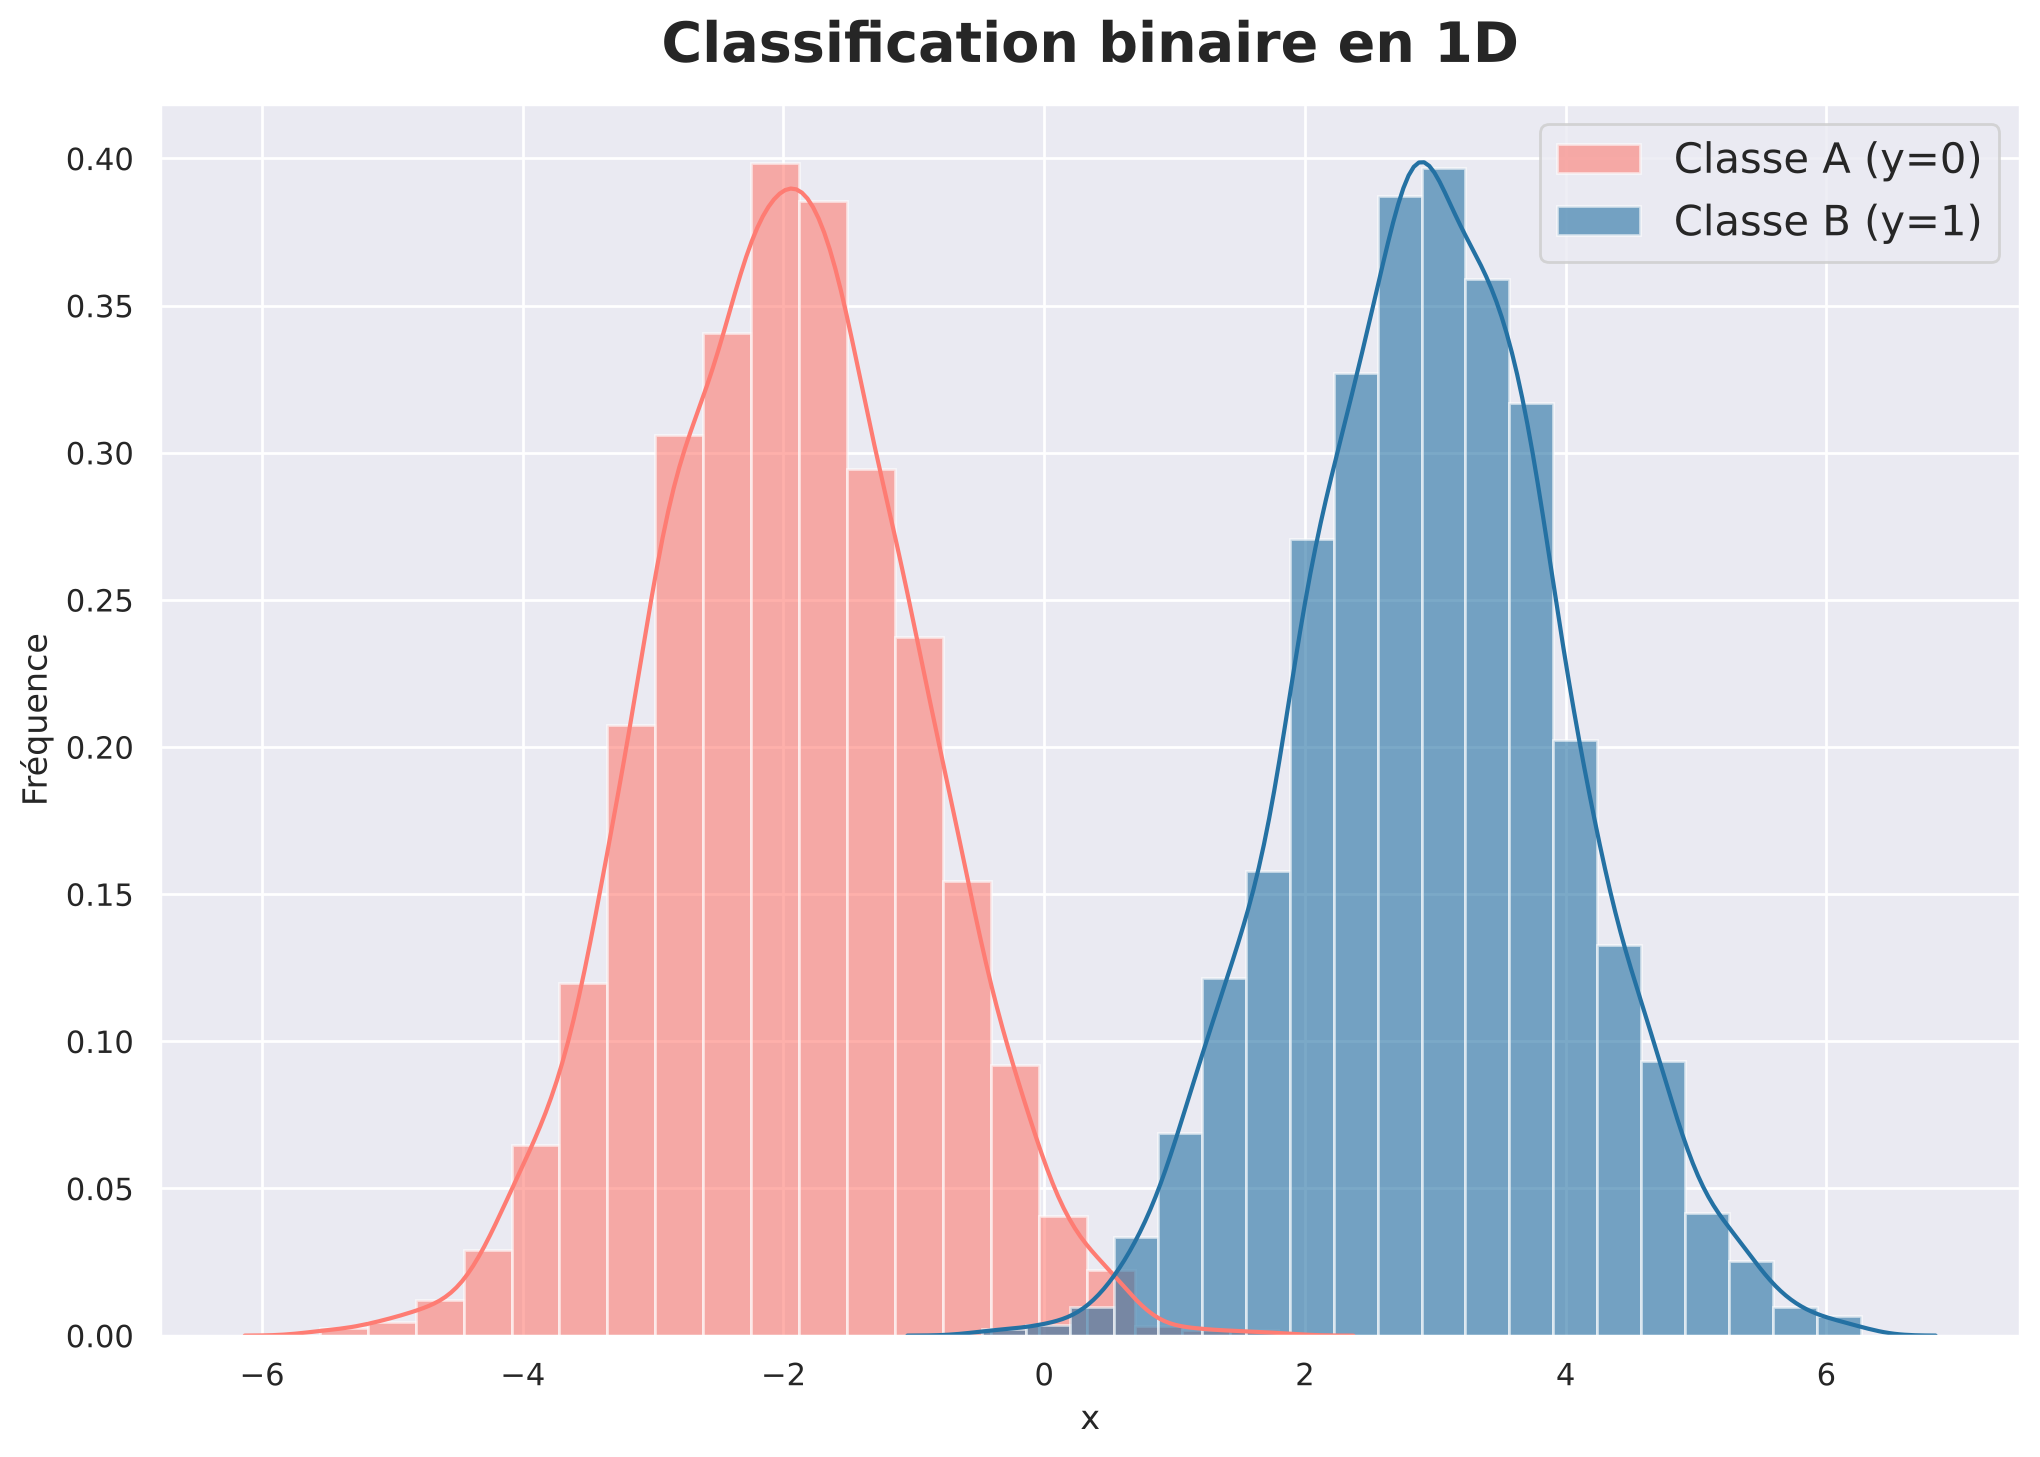

In [4]:
# Générer des données aléatoires
distribution_1 = np.random.normal(mean_1, np.sqrt(variance), num_points)
distribution_2 = np.random.normal(mean_2, np.sqrt(variance), num_points)

fig, ax = plt.subplots(figsize = (12, 8))
# Créer des histogrammes et des graphiques KDE
ax.hist(distribution_1, bins=20, alpha=0.6, label='Classe A (y=0)', density=True, color = colors[0])
ax.hist(distribution_2, bins=20, alpha=0.6, label='Classe B (y=1)', density=True, color = colors[1])
sns.kdeplot(distribution_1, ax = ax, color = colors[0])
sns.kdeplot(distribution_2, ax = ax, color = colors[1])

# Ajouter des étiquettes et une légende
ax.set_xlabel('x')
ax.set_ylabel('Fréquence')
ax.set_title('Classification binaire en 1D', weight = "bold", fontsize = 20, pad = 15)
plt.legend(fontsize = 15)

# Afficher le graphique
plt.show()

### 2.2 Les données vues comme un problème de classification

Pour y voir plus clair, on affiche un échantillon de points sur une droite : on devine facilement une frontière verticale entre les deux classes.

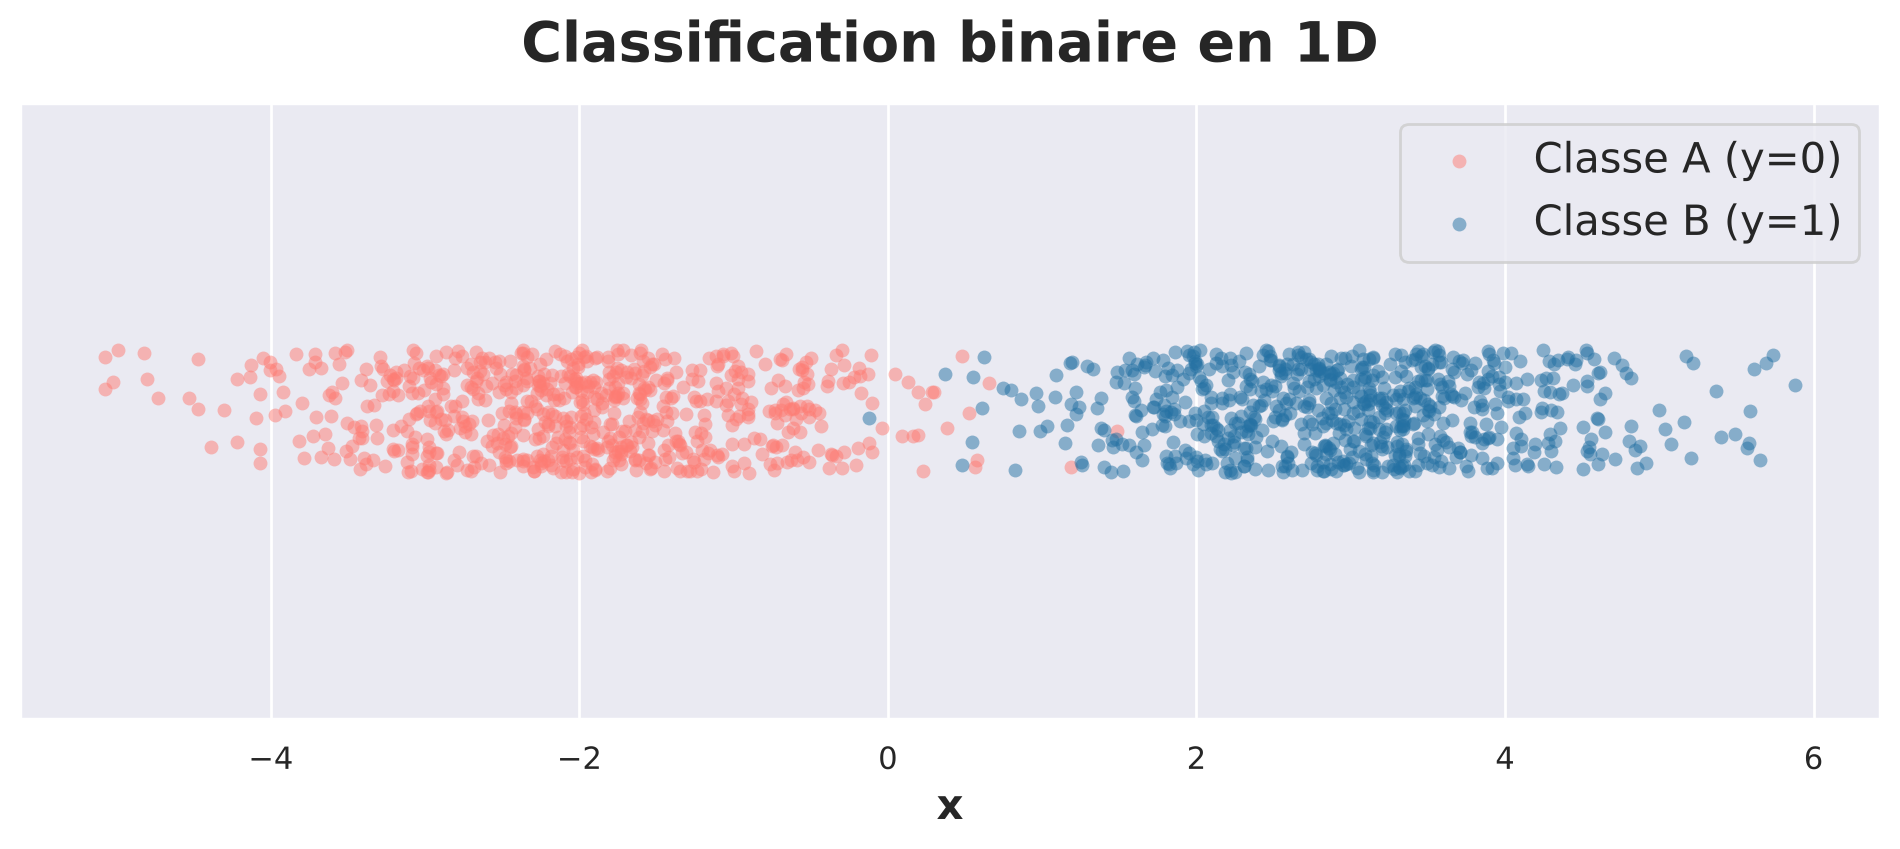

In [5]:
## Échantillonner quelques points de données pour un affichage clair.

fig, ax = plt.subplots(figsize = (12, 4))
# Créer des histogrammes
sns.stripplot(np.random.choice(distribution_1, 700, replace=False), ax = ax, label='Classe A (y=0)', alpha=0.5, color = colors[0], orient='y')
sns.stripplot(np.random.choice(distribution_2, 700, replace=False), ax = ax, label='Classe B (y=1)', alpha=0.5, color = colors[1], orient='y')

# Ajouter des étiquettes et une légende
ax.set_xlabel('x', weight = "bold", fontsize = 15)
ax.set_title('Classification binaire en 1D', weight = "bold", fontsize = 20, pad = 15)
plt.legend(fontsize = 15)

# Afficher le graphique
plt.show()

## 3. La règle de Bayes fait apparaître la sigmoïde

On connaît les conditionnelles p(X | y) (deux gaussiennes) et les probabilités a priori p(y) (1/2 chacune). Avec la règle de Bayes, on obtient la probabilité **postérieure** p(y | X) : la probabilité d'appartenir à une classe sachant la valeur observée.

On ne suppose **rien** sur la forme de cette courbe, on la calcule simplement.

### 3.1 Les postérieures, classe par classe

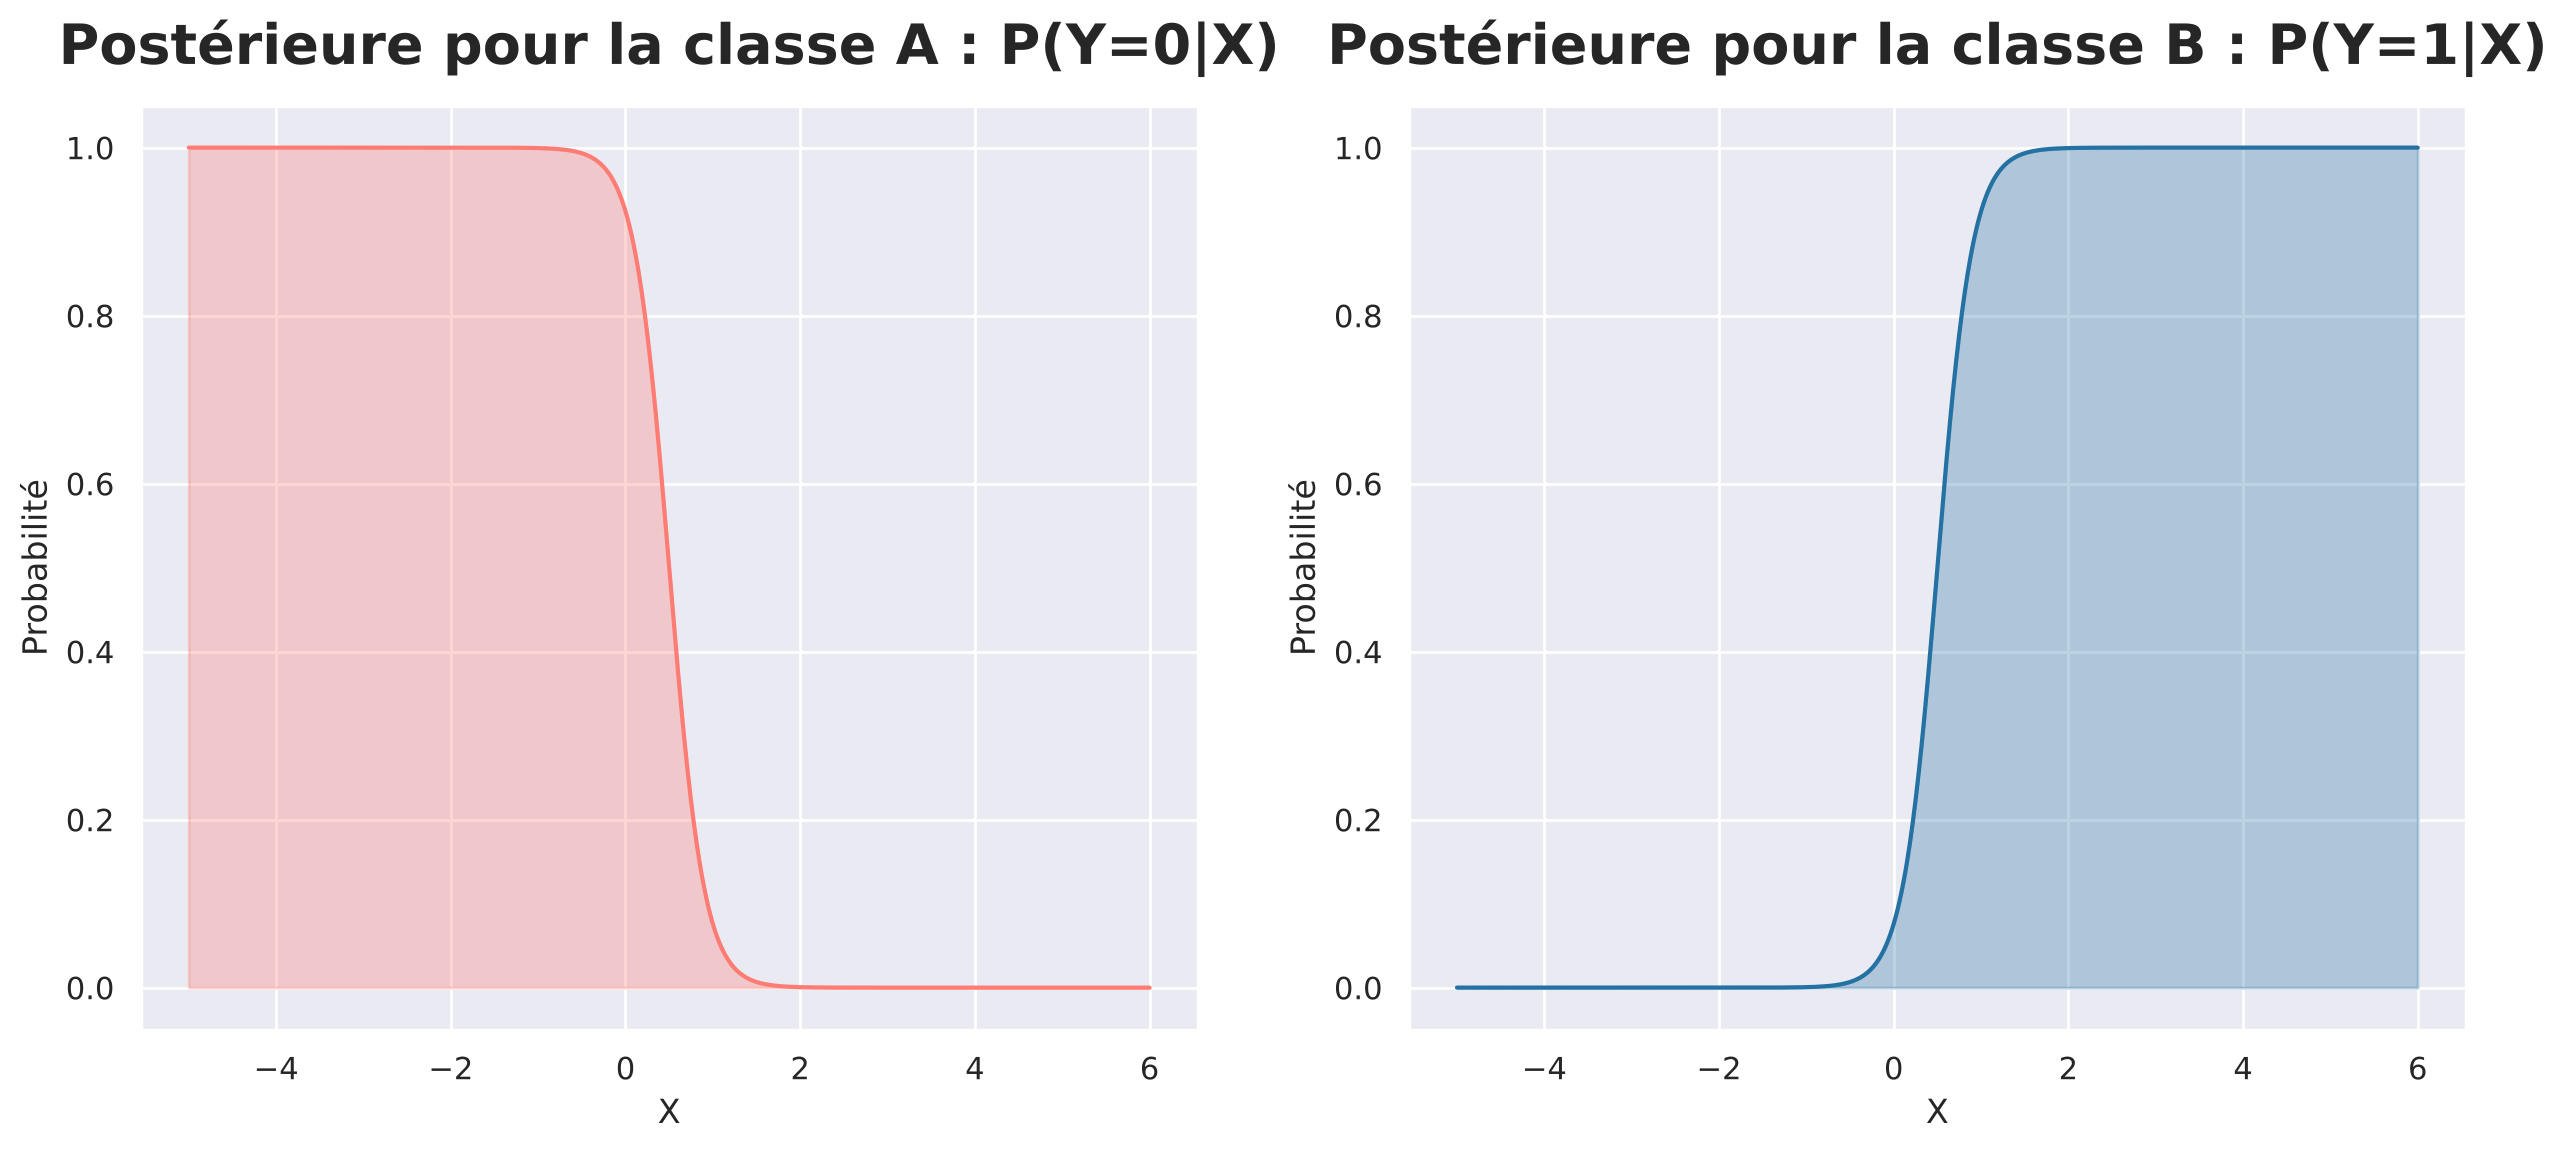

In [6]:
## Modéliser les postérieures avec la règle de Bayes


# Probabilités a priori (en supposant des priors égaux)
prior_1 = prior_2 = 0.5

# Plage de valeurs x pour le graphique
x_range = np.linspace(-5, 6, 1000)

# Calculer les densités conditionnelles de classe (vraisemblances)
likelihood_1 = norm.pdf(x_range, mean_1, np.sqrt(variance))
likelihood_2 = norm.pdf(x_range, mean_2, np.sqrt(variance))

# Calculer les postérieures avec la règle de Bayes
posterior_1 = likelihood_1 * prior_1
posterior_2 = likelihood_2 * prior_2

# Normaliser les postérieurs
posterior_1_1 = posterior_1/(posterior_1 + posterior_2)
posterior_2_1 = posterior_2/(posterior_1 + posterior_2)

fig, ax = plt.subplot_mosaic("AB", figsize = (15, 6))

# Créer le graphique des postérieures
ax["A"].plot(x_range, posterior_1_1, label='Postérieure pour la classe A (P(Y=0|X))', color = colors[0])

# Remplir les zones sous les courbes
ax["A"].fill_between(x_range, posterior_1_1, alpha=0.3, color = colors[0])

# Ajouter des étiquettes et une légende
ax["A"].set_xlabel('X')
ax["A"].set_ylabel('Probabilité')
ax["A"].set_title('Postérieure pour la classe A : P(Y=0|X)', weight = "bold", fontsize = 20, pad = 15)


ax["B"].plot(x_range, posterior_2_1, label='Postérieure pour la classe B (P(Y=1|X))', color = colors[1])

# Remplir les zones sous les courbes.
ax["B"].fill_between(x_range, posterior_2_1, alpha=0.3, color = colors[1])

# Ajouter des étiquettes et une légende
ax["B"].set_xlabel('X')
ax["B"].set_ylabel('Probabilité')
ax["B"].set_title('Postérieure pour la classe B : P(Y=1|X)', weight = "bold", fontsize = 20, pad = 15)
# plt.legend()

# Afficher le graphique
plt.show()

### 3.2 Les deux postérieures sur un même graphique

Les deux courbes se croisent à la frontière de décision et leur somme vaut toujours 1 (c'est la normalisation de Bayes). La postérieure de la classe B a une forme en S : on va montrer qu'il s'agit exactement d'une sigmoïde.

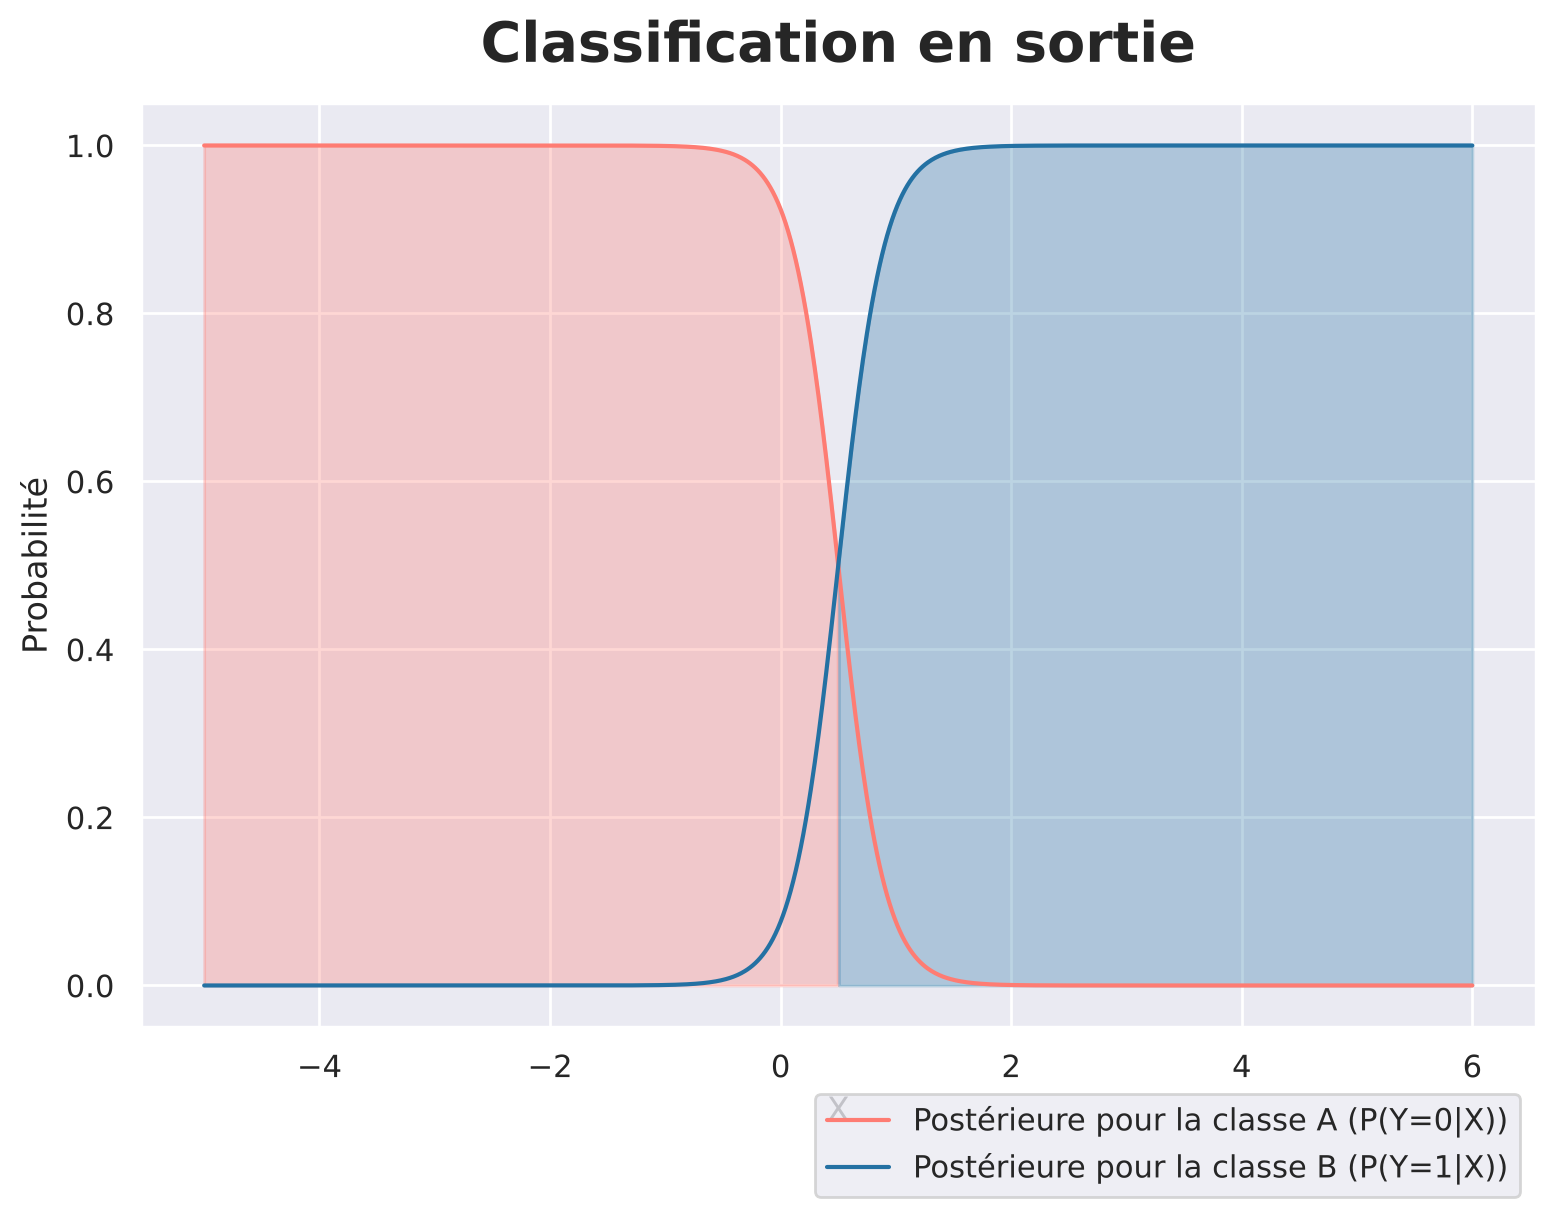

In [7]:
## Modéliser les postérieures à l’aide de la règle de Bayes dans un graphique combiné

# Probabilités a priori (en supposant des priors égaux)
prior_1 = prior_2 = 0.5

# Plage de valeurs x pour le graphique
x_range = np.linspace(-5, 6, 1000)

# Calculer les densités conditionnelles de classe (vraisemblances)
likelihood_1 = norm.pdf(x_range, mean_1, np.sqrt(variance))
likelihood_2 = norm.pdf(x_range, mean_2, np.sqrt(variance))

# Calculer les postérieures avec la règle de Bayes
posterior_1 = likelihood_1 * prior_1
posterior_2 = likelihood_2 * prior_2

# Normaliser les postérieures
posterior_1_1 = posterior_1/(posterior_1 + posterior_2)
posterior_2_1 = posterior_2/(posterior_1 + posterior_2)

fig, ax = plt.subplots(figsize = (9, 6))

# Créer le graphique des postérieures
ax.plot(x_range, posterior_1_1, label='Postérieure pour la classe A (P(Y=0|X))', color = colors[0])
ax.plot(x_range, posterior_2_1, label='Postérieure pour la classe B (P(Y=1|X))', color = colors[1])

# Remplir les zones sous les courbes
threshold = 0.5
ax.fill_between(x_range, posterior_1_1, where=(x_range < threshold), alpha=0.3, color = colors[0])
ax.fill_between(x_range, posterior_2_1, where=(x_range > threshold), alpha=0.3, color = colors[1])


# Ajouter des étiquettes et une légende
ax.set_xlabel('X')
ax.set_ylabel('Probabilité')
ax.set_title('Classification en sortie', weight = "bold", fontsize = 20, pad = 15)
plt.legend(loc='lower right', bbox_to_anchor=(1, -0.2))

# plt.savefig("binary_posterior1.jpeg", dpi=300, bbox_inches="tight")

# Afficher le graphique
plt.show()

### 3.3 Vérifions la dérivation du mini-cours

Avec deux gaussiennes de même variance σ² = 1 et des moyennes de −2 et 3, la dérivation donne p(y=1 | x) = sigmoïde(z) avec **z = 5x − 5/2**. Si c'est juste, une régression logistique entraînée sur ces données doit retrouver un coefficient proche de **5** et une constante proche de **−2,5**.

In [8]:
from sklearn.linear_model import LogisticRegression

x_1d = np.concatenate([distribution_1, distribution_2]).reshape(-1, 1)
y_1d = np.concatenate([np.zeros(num_points), np.ones(num_points)])

logreg_1d = LogisticRegression(C=1e6).fit(x_1d, y_1d)   # C très grand : quasiment pas de régularisation
print(f"Coefficient : {logreg_1d.coef_[0][0]:.2f}  (théorie : 5)")
print(f"Constante   : {logreg_1d.intercept_[0]:.2f}  (théorie : -2.5)")

Coefficient : 5.23  (théorie : 5)
Constante   : -2.73  (théorie : -2.5)


## 4. Quand les hypothèses cassent

La sigmoïde est apparue parce qu'on a supposé **mêmes variances** et **mêmes probabilités a priori** : le terme quadratique en x s'est simplifié. Que se passe-t-il si on retire ces hypothèses ?

On compare deux jeux de données en 2D :
- **à gauche** : mêmes priors et mêmes variances ;
- **à droite** : priors différents (200 contre 500 points) et variances différentes.

Pour chacun, on trace les régions de décision calculées avec la règle de Bayes.

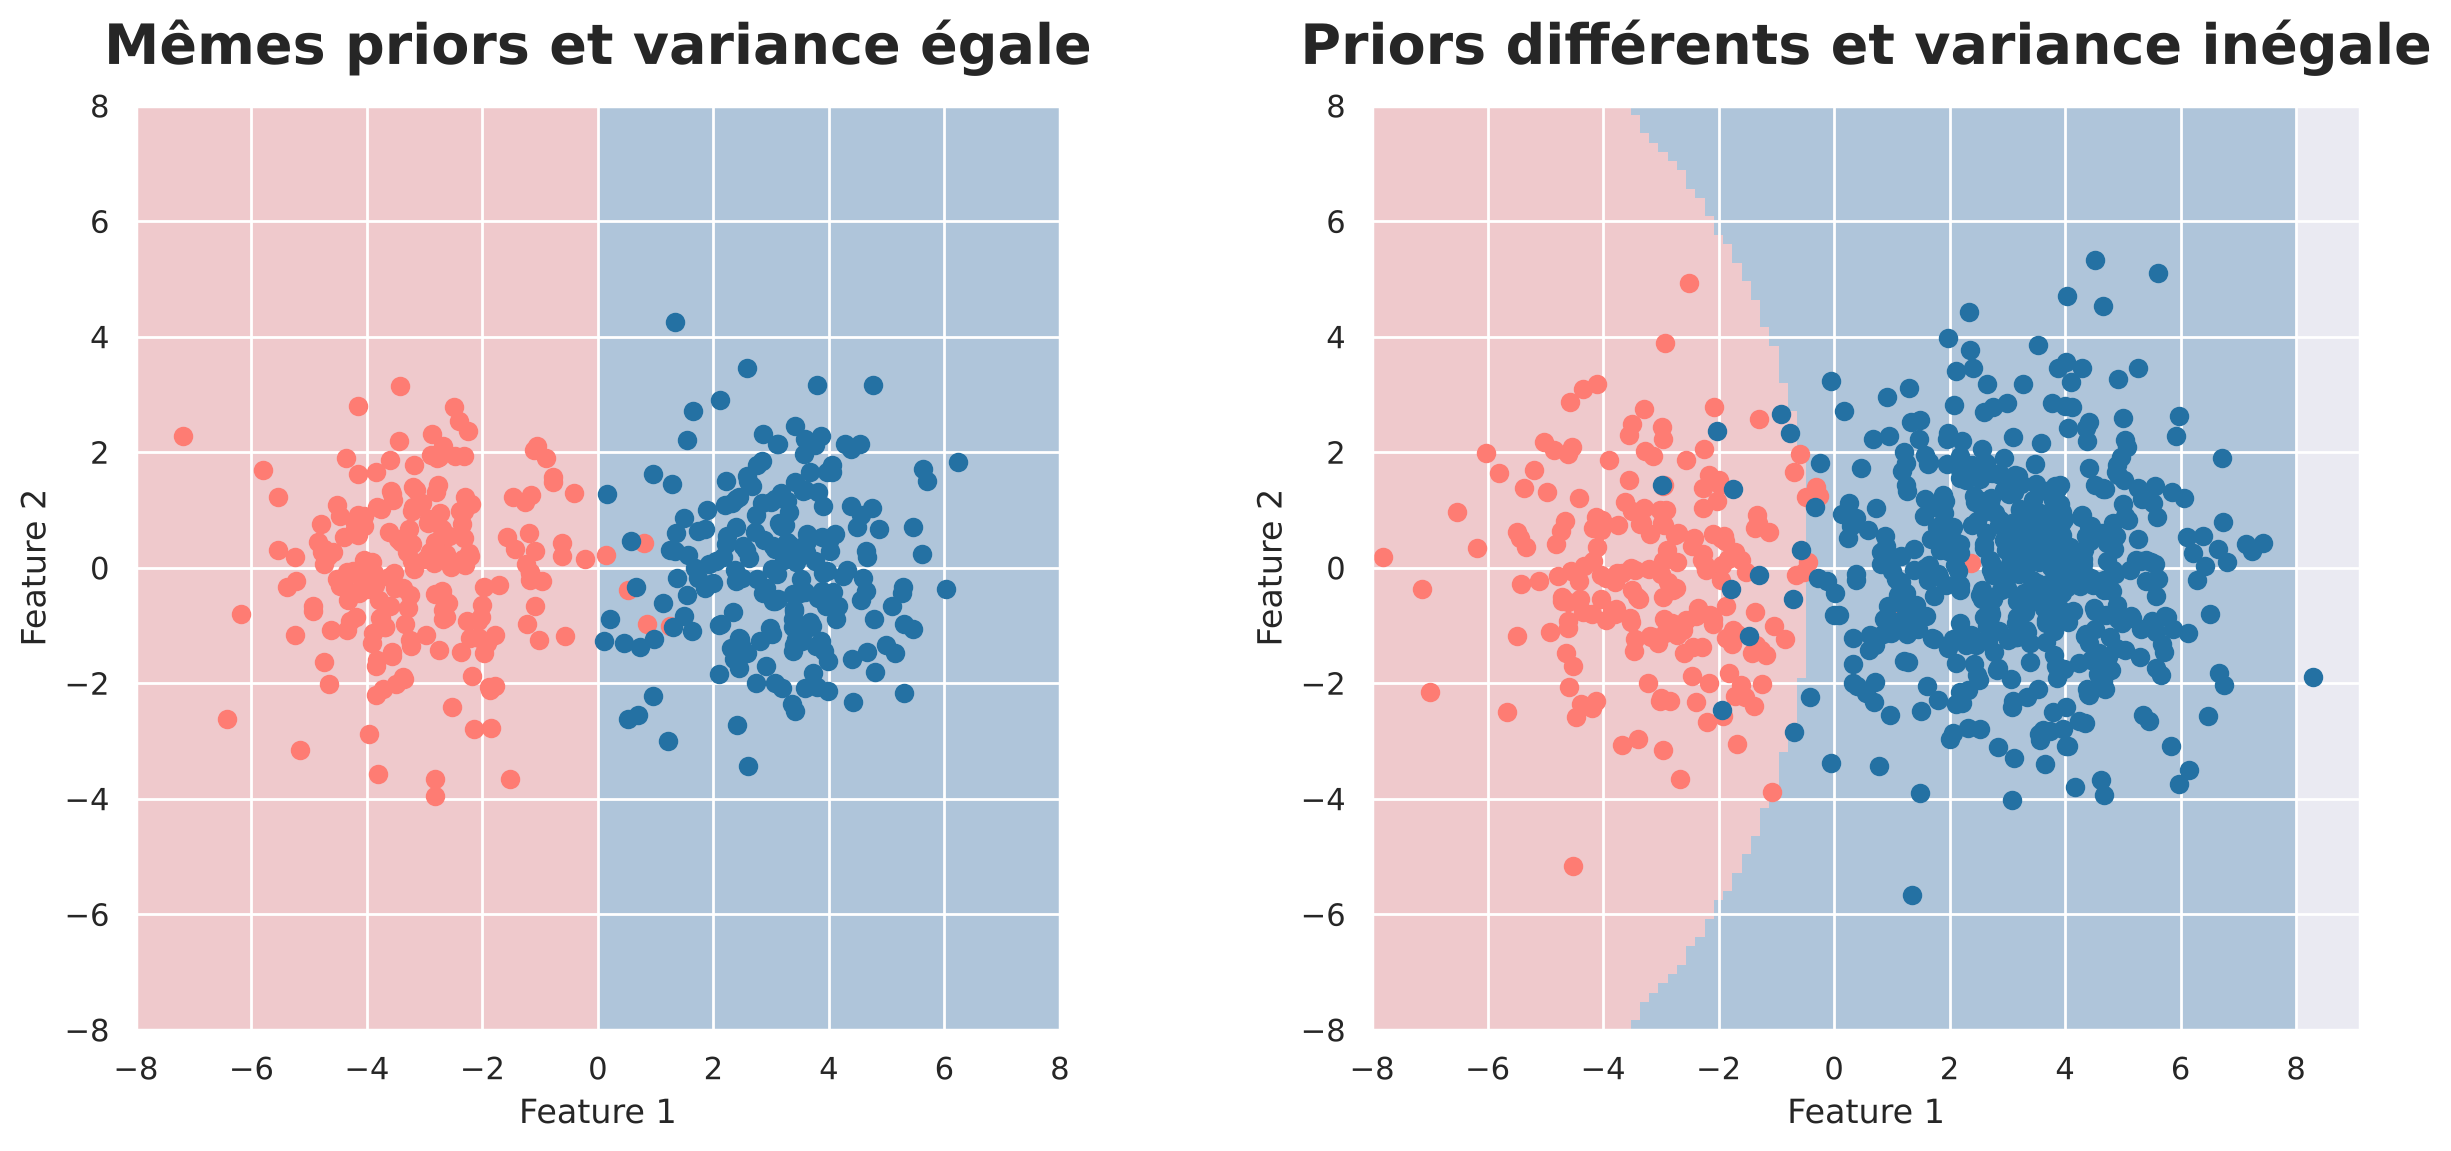

In [9]:
# Paramètres
fig, ax = plt.subplot_mosaic("AB", figsize = (15, 6))

num_points11 = 200
num_points21 = 200
mean_1 = np.array([-3, 0])
mean_2 = np.array([3, 0])
covariance_1 = np.array([[2, 0], [0, 2]])
covariance_2 = np.array([[2, 0], [0, 2]])

# Générer des données aléatoires
distribution_11 = np.random.multivariate_normal(mean_1, covariance_1, num_points11)
distribution_21 = np.random.multivariate_normal(mean_2, covariance_2, num_points21)

# Probabilités a priori (en supposant des priors égaux)
prior_1 = num_points11/(num_points11+num_points21)
prior_2 = num_points21/(num_points11+num_points21)

# Plage de valeurs x et y pour le graphique
x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)
points = np.c_[X.ravel(), Y.ravel()]

# Calculer les densités conditionnelles de classe (vraisemblances)
likelihood_1 = multivariate_normal.pdf(points, mean_1, covariance_1)
likelihood_2 = multivariate_normal.pdf(points, mean_2, covariance_2)

# Redimensionner les vraisemblances pour correspondre aux dimensions X, Y
likelihood_1 = likelihood_1.reshape(X.shape)
likelihood_2 = likelihood_2.reshape(X.shape)

# Calculer les postérieures avec la règle de Bayes
posterior_1 = likelihood_1 * prior_1
posterior_2 = likelihood_2 * prior_2

# Normaliser les postérieures
posterior_1_1 = posterior_1/(posterior_1 + posterior_2)
posterior_2_1 = posterior_2/(posterior_1 + posterior_2)

decision_regions = np.where(posterior_1_1 > posterior_2_1, 1, 0)


ax["A"].imshow(decision_regions, extent=(-8, 8, -8, 8), cmap=ListedColormap(colors[0:2:][::-1]), alpha=0.3)

# Ajouter les nuages de points pour les données
ax["A"].scatter(distribution_11[:, 0], distribution_11[:, 1], c=colors[0], label='Classe A')
ax["A"].scatter(distribution_21[:, 0], distribution_21[:, 1], c=colors[1], label='Classe B')

# Ajouter des étiquettes et une légende
ax["A"].set_xlabel('Feature 1')
ax["A"].set_ylabel('Feature 2')
ax["A"].set_title('Mêmes priors et variance égale', weight = "bold", fontsize = 20, pad = 15)



num_points12 = 200
num_points22 = 500
mean_1 = np.array([-3, 0])
mean_2 = np.array([3, 0])
covariance_1 = np.array([[2, 0], [0, 2]])
covariance_2 = np.array([[3, 0], [0, 3]])

# Générer des données aléatoires
distribution_12 = np.random.multivariate_normal(mean_1, covariance_1, num_points12)
distribution_22 = np.random.multivariate_normal(mean_2, covariance_2, num_points22)

# Probabilités a priori (en supposant des priors égaux)
prior_1 = num_points12/(num_points12+num_points22)
prior_2 = num_points22/(num_points12+num_points22)

# Plage de valeurs x et y pour le graphique
x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)
points = np.c_[X.ravel(), Y.ravel()]

# Calculer les densités conditionnelles de classe (vraisemblances)
likelihood_1 = multivariate_normal.pdf(points, mean_1, covariance_1)
likelihood_2 = multivariate_normal.pdf(points, mean_2, covariance_2)

# Redimensionner les vraisemblances pour correspondre aux dimensions X, Y
likelihood_1 = likelihood_1.reshape(X.shape)
likelihood_2 = likelihood_2.reshape(X.shape)

# Calculer les postérieures avec la règle de Bayes
posterior_1 = likelihood_1 * prior_1
posterior_2 = likelihood_2 * prior_2

# Normaliser les postérieures
posterior_1_1 = posterior_1/(posterior_1 + posterior_2)
posterior_2_1 = posterior_2/(posterior_1 + posterior_2)

decision_regions = np.where(posterior_1_1 > posterior_2_1, 1, 0)


ax["B"].imshow(decision_regions, extent=(-8, 8, -8, 8), cmap=ListedColormap(colors[0:2:][::-1]), alpha=0.3)

# Ajouter les nuages de points pour les données
ax["B"].scatter(distribution_12[:, 0], distribution_12[:, 1], c=colors[0], label='Classe A')
ax["B"].scatter(distribution_22[:, 0], distribution_22[:, 1], c=colors[1], label='Classe B')

# Ajouter des étiquettes et une légende
ax["B"].set_xlabel('Feature 1')
ax["B"].set_ylabel('Feature 2')
ax["B"].set_title('Priors différents et variance inégale', weight = "bold", fontsize = 20, pad = 15)

# Afficher le graphique
plt.show()

## 5. Et la régression logistique dans tout ça ?

On entraîne maintenant une régression logistique sur ces deux mêmes jeux de données. Elle produit toujours une frontière **linéaire** : à gauche elle colle aux régions de Bayes, à droite elle ne peut plus les suivre. C'est le compromis entre un modèle **génératif** (Bayes, qui modélise les distributions) et un modèle **discriminatif** (régression logistique, qui modélise directement la frontière).

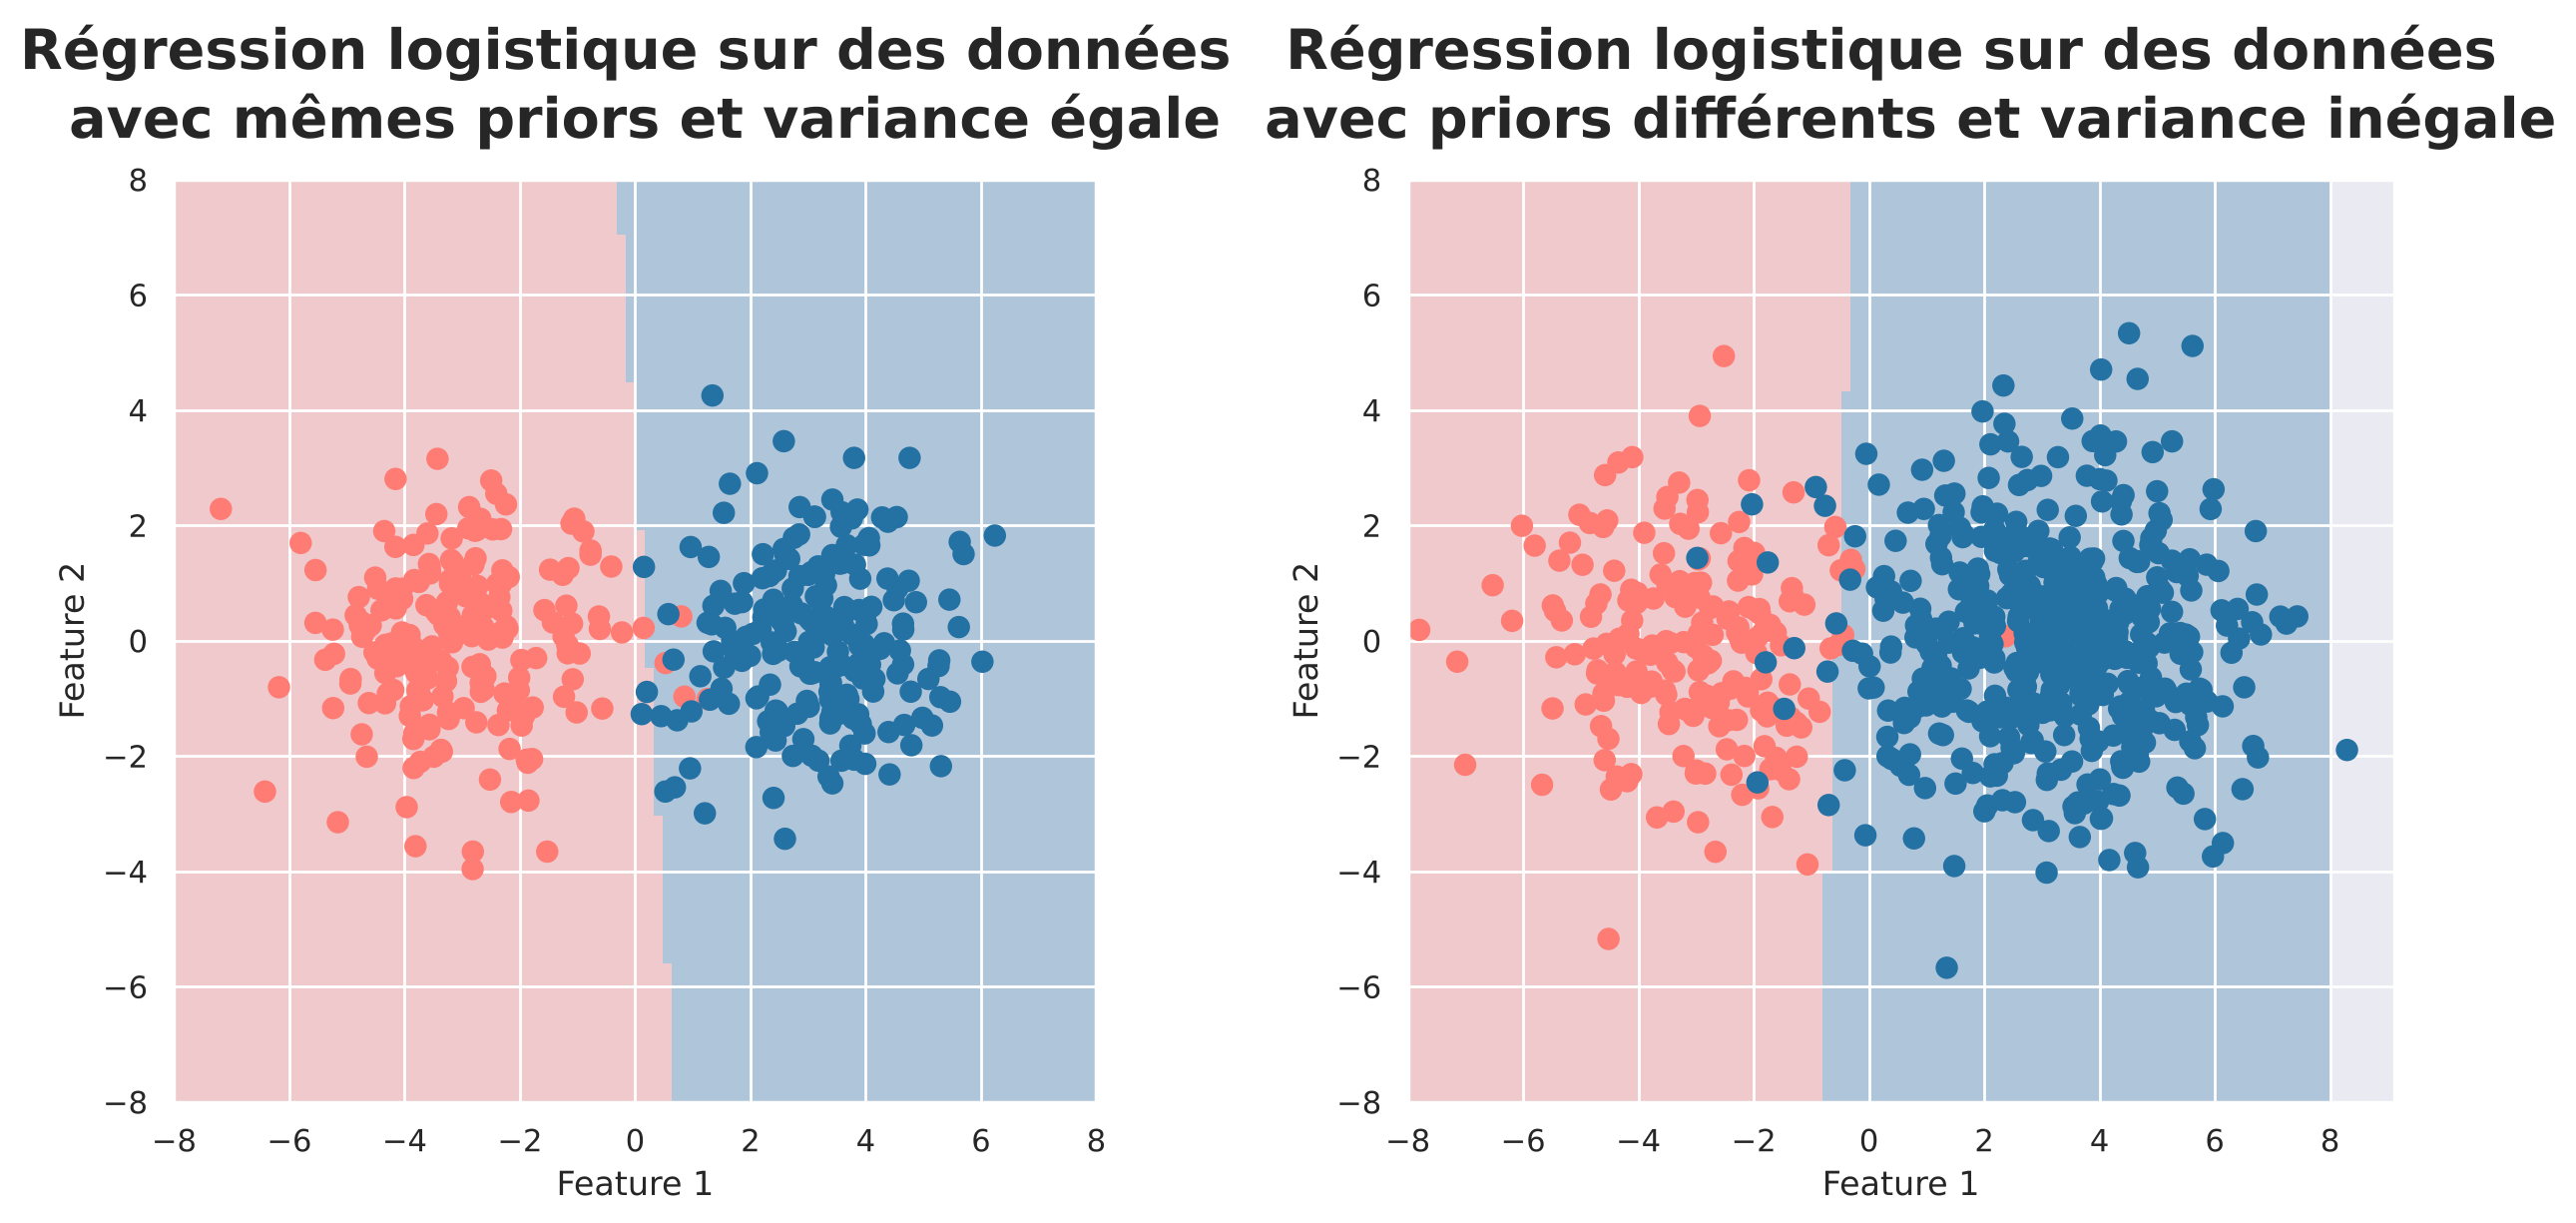

In [10]:
fig, ax = plt.subplot_mosaic("AB", figsize = (15, 6))

data = np.vstack((distribution_11, distribution_21))
labels = np.hstack((np.ones(num_points11), np.zeros(num_points21)))

# Ajuster le modèle de régression logistique
model = LogisticRegression()
model.fit(data, labels)

# Plage de valeurs x et y pour le graphique
x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)
points = np.c_[X.ravel(), Y.ravel()]

# Prédire les probabilités avec le modèle de régression logistique ajusté
probabilities = model.predict_proba(points)
decision_regions = probabilities[:, 1].reshape(X.shape)

# Couleurs personnalisées pour les régions de décision
color_map = ['lightblue', 'lightcoral']

# Créer une carte de chaleur avec des couleurs personnalisées pour les régions de décision
ax["A"].imshow(decision_regions, extent=(-8, 8, -8, 8), cmap=ListedColormap(colors[0:2:][::-1]), alpha=0.3)

# Ajouter les nuages de points pour les données
ax["A"].scatter(data[:, 0], data[:, 1], c=labels, cmap=ListedColormap(colors[0:2:][::-1]), marker='o', s=50)

# Ajouter des étiquettes et une légende
ax["A"].set_xlabel('Feature 1')
ax["A"].set_ylabel('Feature 2')
ax["A"].set_title('Régression logistique sur des données \n avec mêmes priors et variance égale', weight = "bold", fontsize = 20, pad = 15)


data = np.vstack((distribution_12, distribution_22))
labels = np.hstack((np.ones(num_points21), np.zeros(num_points22)))

# Ajuster le modèle de régression logistique
model = LogisticRegression()
model.fit(data, labels)

# Plage de valeurs x et y pour le graphique
x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)
points = np.c_[X.ravel(), Y.ravel()]

# Prédire les probabilités avec le modèle de régression logistique ajusté
probabilities = model.predict_proba(points)
decision_regions = probabilities[:, 1].reshape(X.shape)

# Créer une carte de chaleur avec des couleurs personnalisées pour les régions de décision
ax["B"].imshow(decision_regions, extent=(-8, 8, -8, 8), cmap=ListedColormap(colors[0:2:][::-1]), alpha=0.3)

# Ajouter les nuages de points pour les données
ax["B"].scatter(data[:, 0], data[:, 1], c=labels, cmap=ListedColormap(colors[0:2:][::-1]), marker='o', s=50)

# Ajouter des étiquettes et une légende
ax["B"].set_xlabel('Feature 1')
ax["B"].set_ylabel('Feature 2')
ax["B"].set_title('Régression logistique sur des données \n avec priors différents et variance inégale', weight = "bold", fontsize = 20, pad = 15)


# Afficher le graphique
plt.show()

---

## Pour aller plus loin

- [Régression Linéaire : d'où viennent vraiment ses hypothèses ?](https://www.monshotdata.com/p/hypotheses-regression-lineaire) — la même démarche appliquée à la régression linéaire
- [Modèles Linéaires Généralisés (GLM) : la régression linéaire réinventée](https://www.monshotdata.com/p/modeles-lineaires-generalises-glm) — la famille de modèles dont la régression logistique fait partie
- [Comprendre les Modèles de Mélange Gaussien (GMMs)](https://www.monshotdata.com/p/modeles-melange-gaussien-gmm) — un modèle génératif à base de gaussiennes